# Roman I-Sim: two models of one simulated galaxy

BayMorph's diagnostics for two fits, a single Sérsic and a bulge plus disc, of one galaxy in an STScI Roman I-Sim exposure: simulation r00342, WFI01, F184, 294 s, public in the [Roman Research Nexus bucket](https://stpubdata.s3.amazonaws.com/roman/nexus/soc_simulations/r00342/l2/). The PSF is the CRDS reference ePSF of the exposure. The fits ran with BayMorph's production runner and nested sampling; this notebook only reads their products, which are not distributed.

In [1]:
import json
from pathlib import Path

import numpy as np
import yaml
from astropy.io import fits

from baymorph.analysis.radial_profiles import radial_profile_statistics_from_image as profile
from baymorph.plotting import corner_plot, plot_log_data_model_residual, plot_radial_profile_diagnostics

run = Path("../runs/roman_isim_r00342_epsf_2026-10-29/r00342_f184_B_epsf")
data = fits.getdata(run / "image_preparation/prepared_image.fits")
mask = np.load(run / "image_preparation/fitting_mask.npy")
models = {"Single Sérsic": run / "fits/single_sersic", "Bulge + disc": run / "fits/bulge_disk"}

## Data, model and residuals

The central 81 × 81 px. The standardized residual uses the noise model of the fit on every pixel, also on those the fit masked, such as the neighbour on the left.

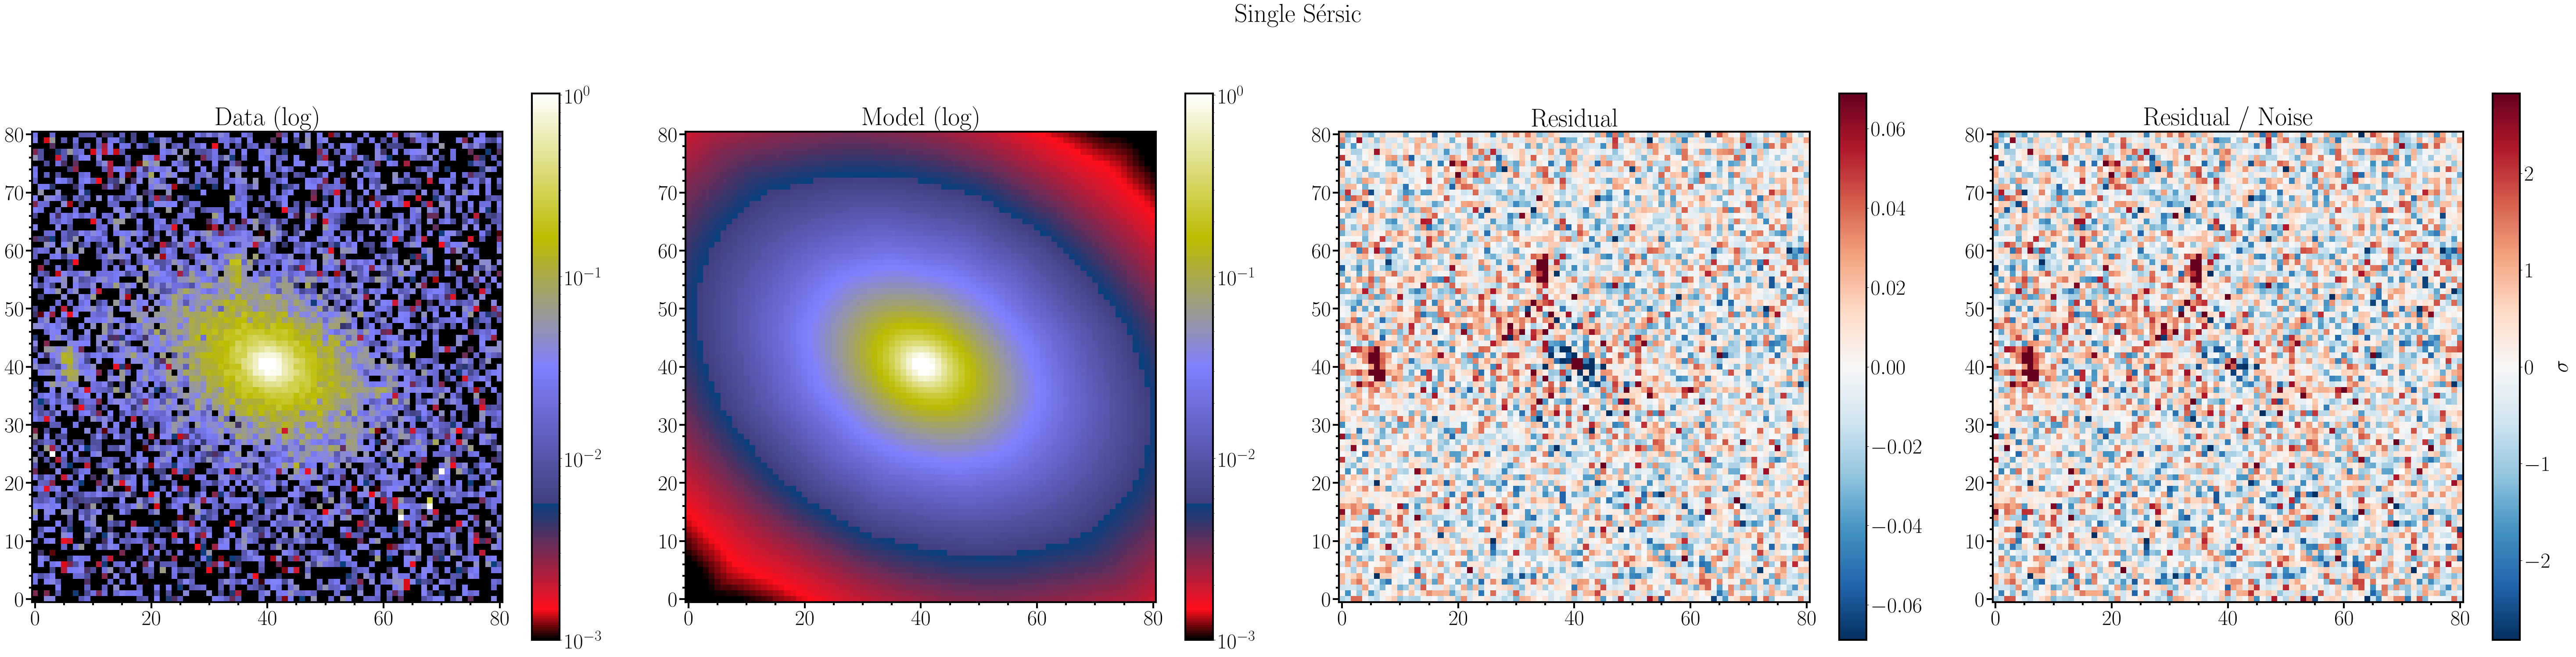

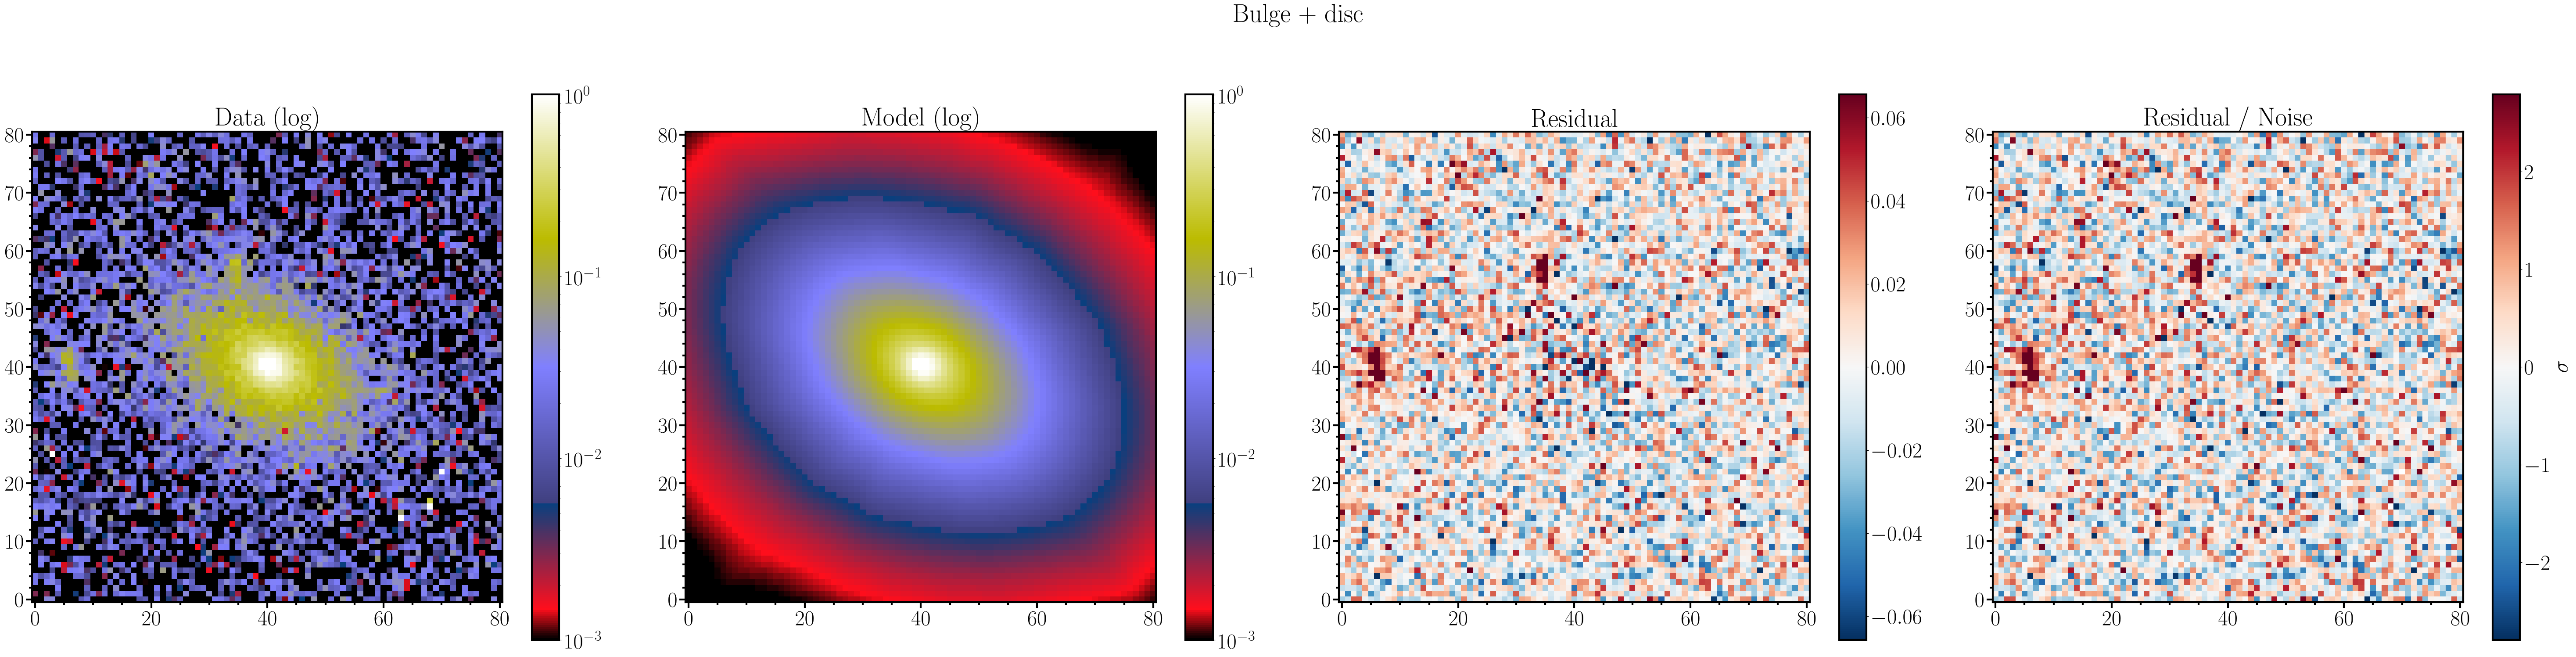

In [2]:
zoom = np.s_[99:180, 99:180]
for name, fit in models.items():
    model = np.load(fit / "best_model_image.npy")
    # The noise scale of the fit on every pixel: sky variance plus source / gain.
    gain = yaml.safe_load((fit / "config_resolved.yaml").read_text())["fit"]["likelihood"]["effective_gain"]["gain"]
    source = model - json.loads((fit / "best_parameters.json").read_text())["background_level"]
    scale = np.sqrt(np.load(fit / "noise.npy") ** 2 + np.clip(source, 0, None) / gain)
    residual = (data - model) / scale
    plot_log_data_model_residual(data[zoom], model[zoom], norm_residual=residual[zoom], title=name)

## Radial profiles

Elliptical annuli with the geometry of the single-Sérsic fit.

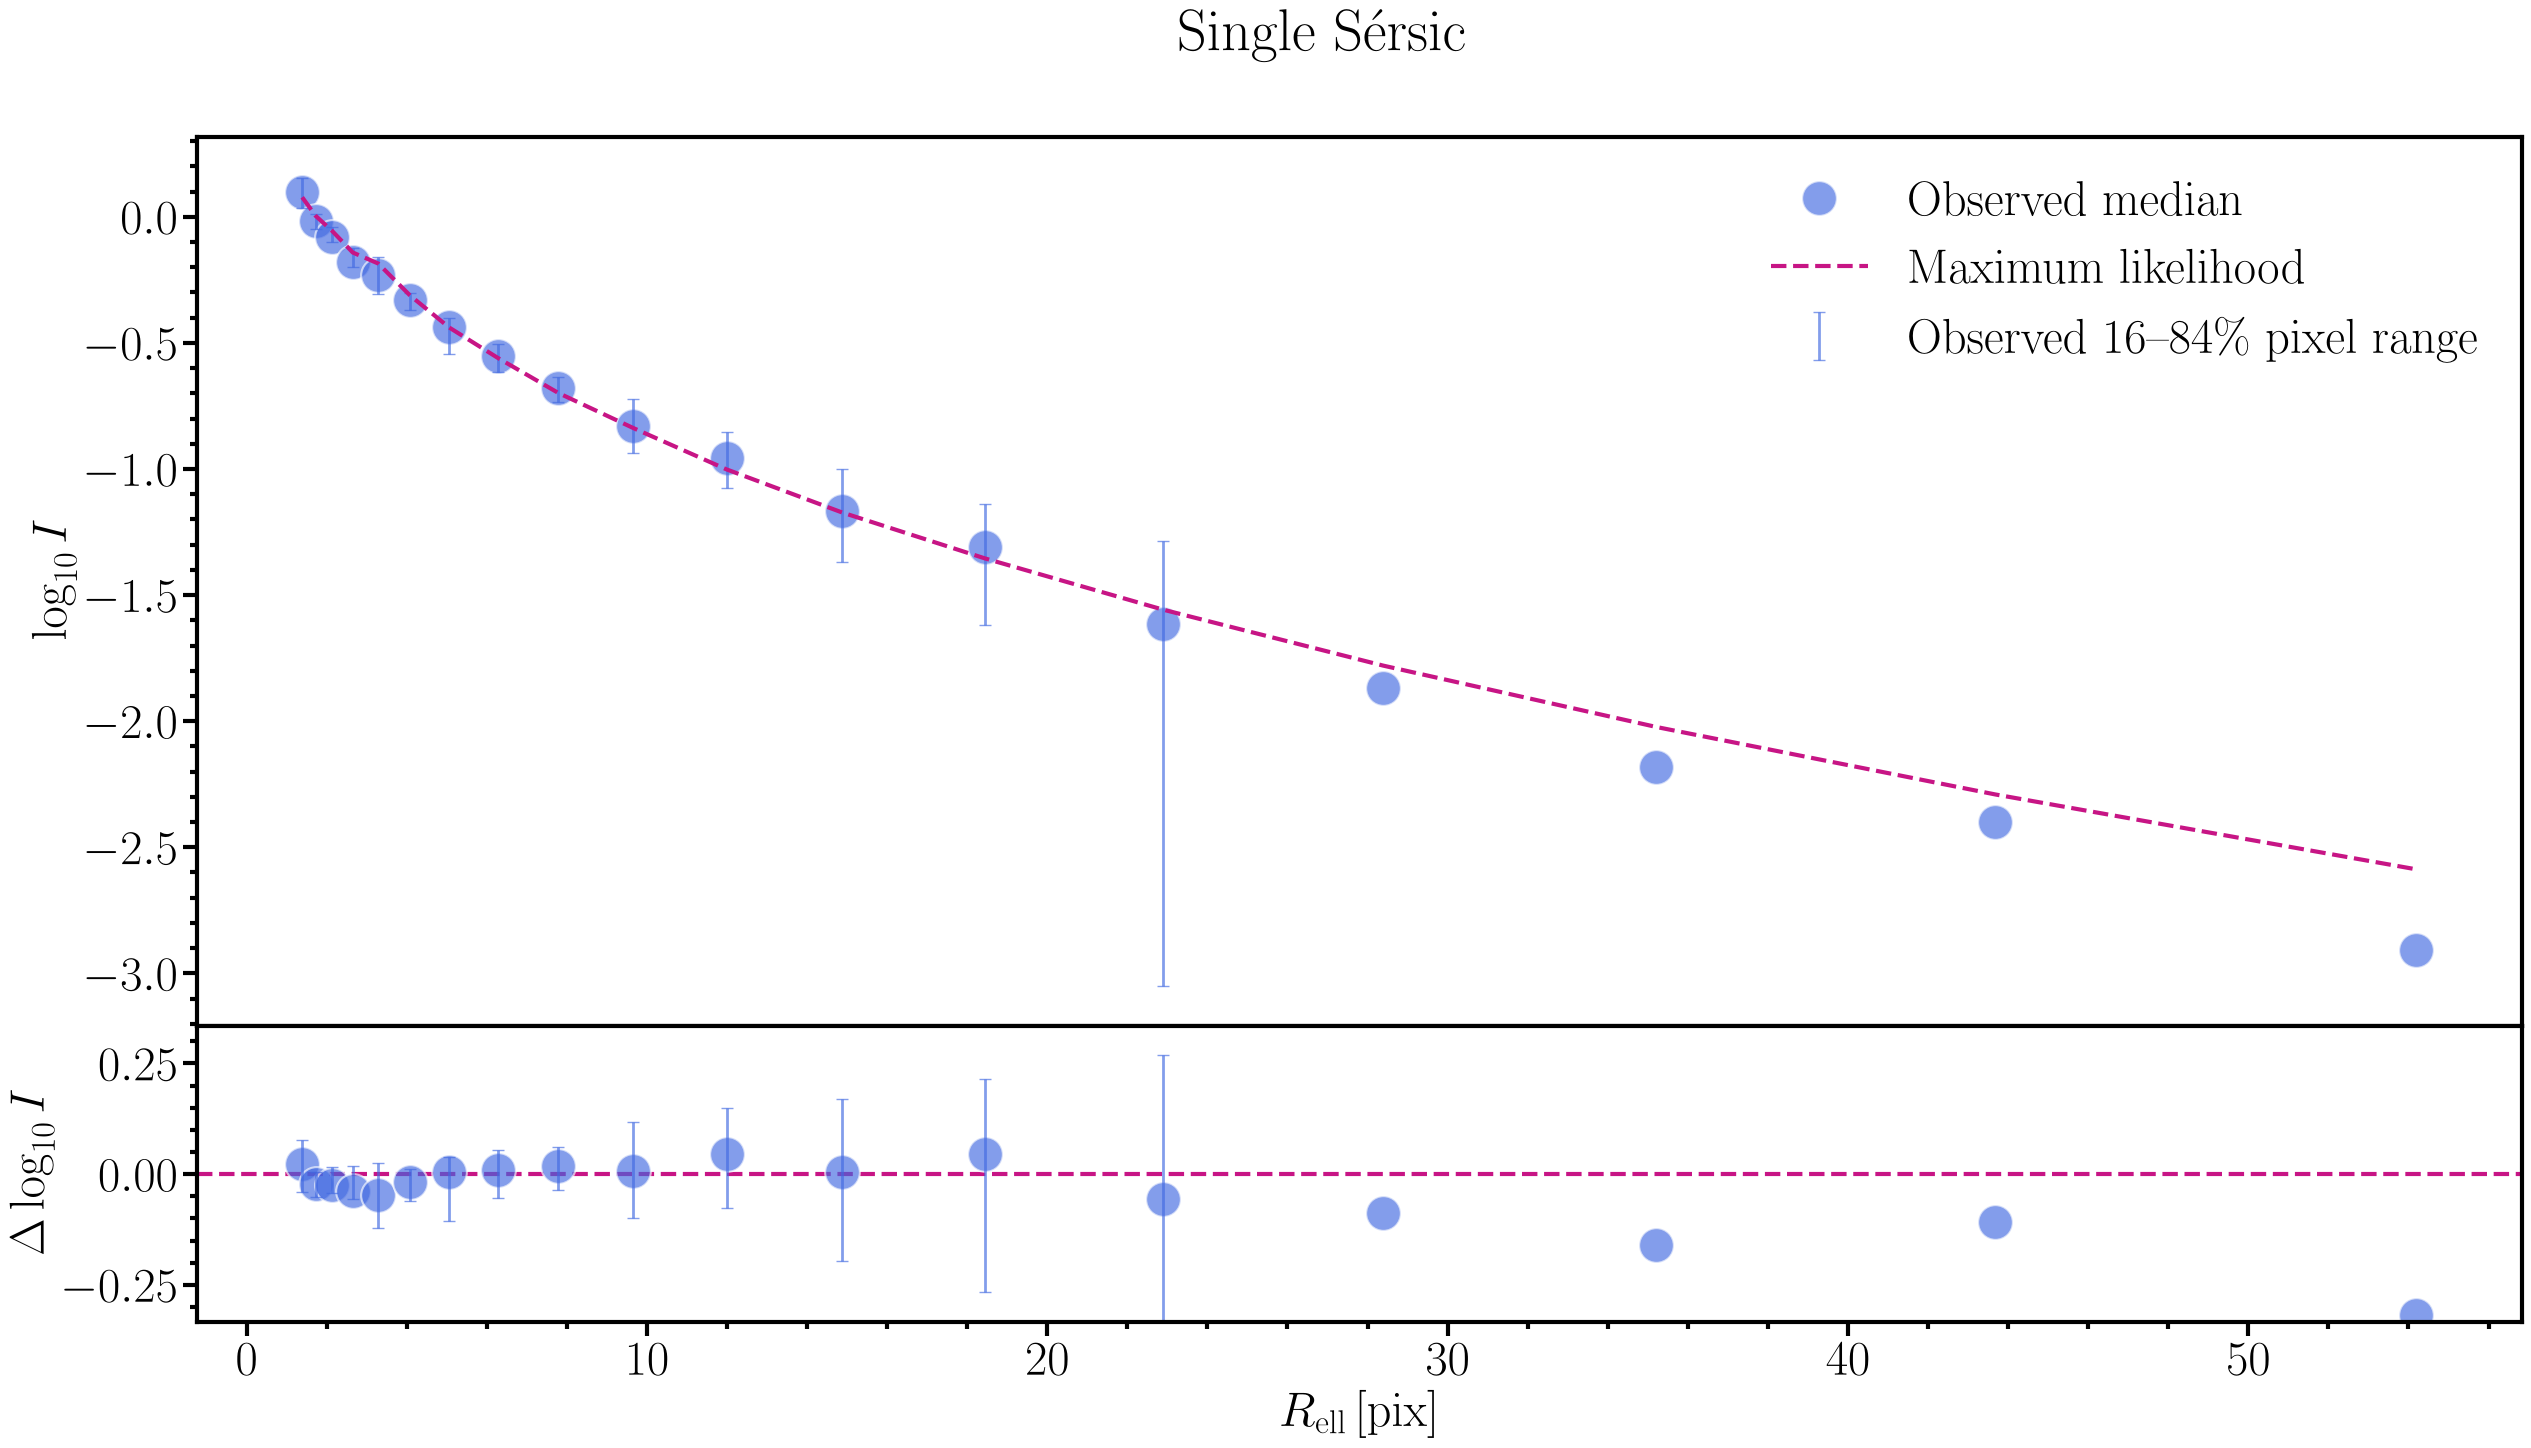

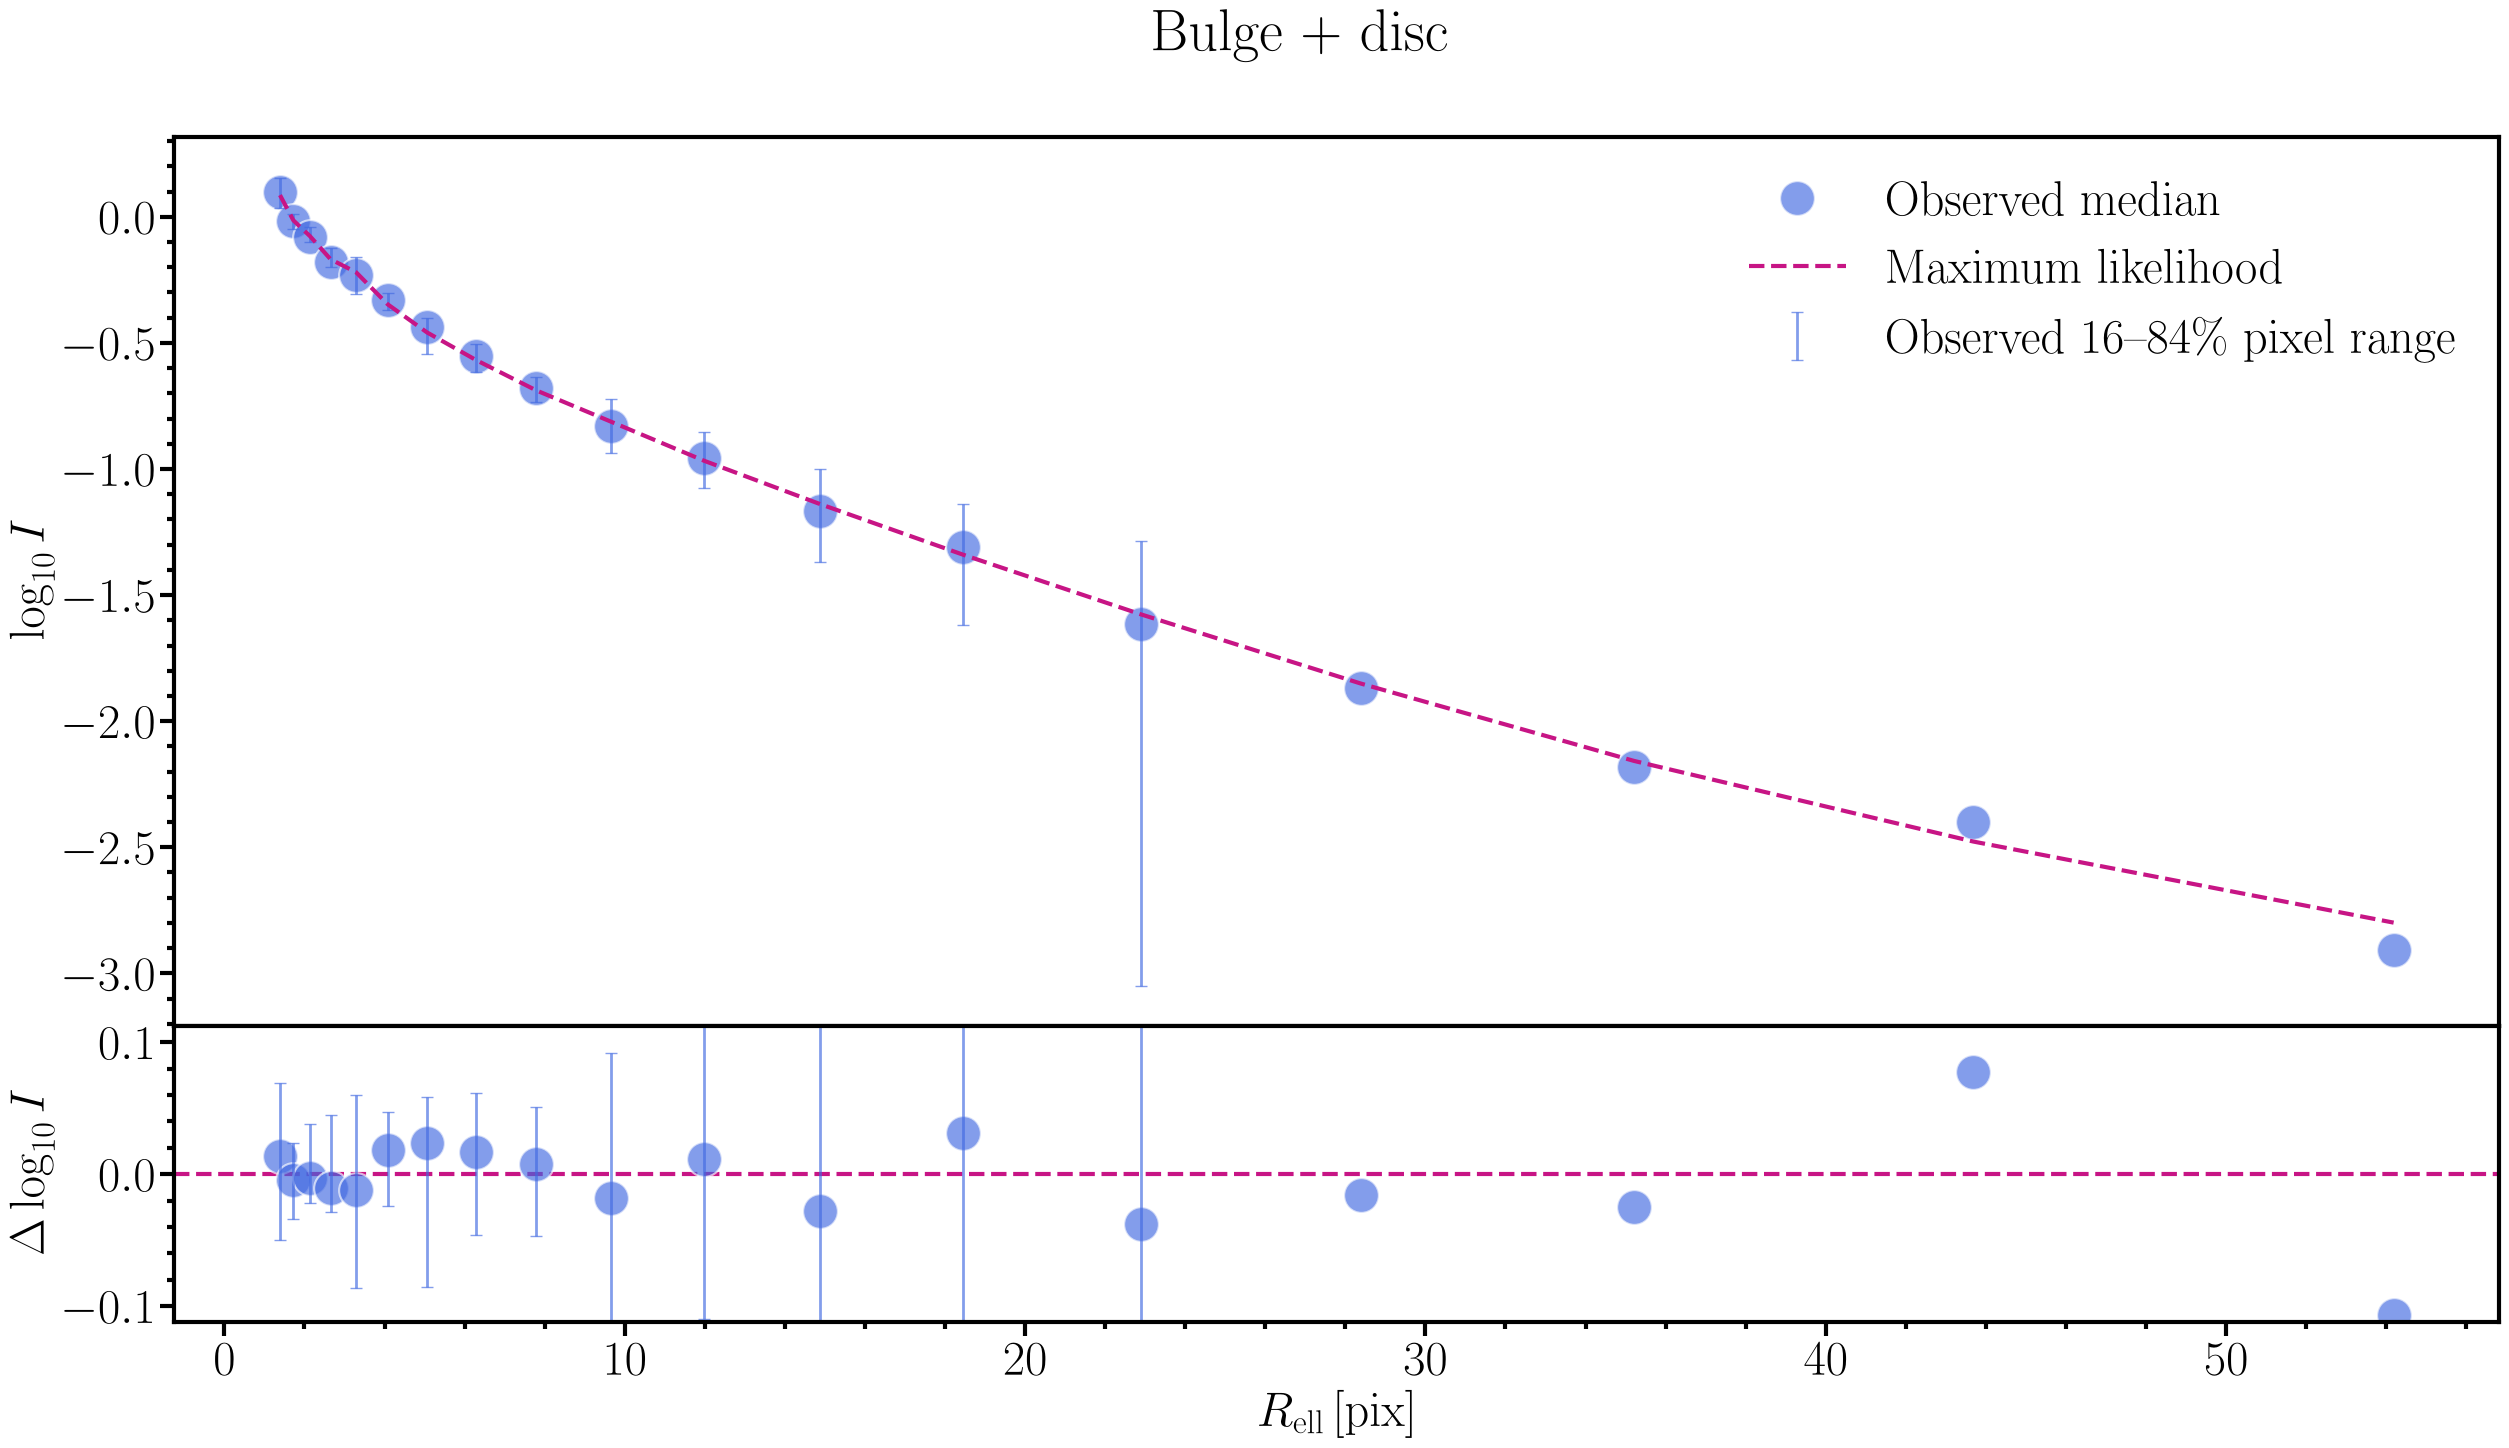

In [3]:
p = json.loads((models["Single Sérsic"] / "best_parameters.json").read_text())
annuli = dict(radii=np.geomspace(1, 60, 20), mask=mask, axis_ratio=p["q"], position_angle=p["theta"])
observed = profile(data, p["x0"], p["y0"], **annuli)
for name, fit in models.items():
    model = profile(np.load(fit / "best_model_image.npy"), p["x0"], p["y0"], **annuli)
    plot_radial_profile_diagnostics(
        observed.radius, observed.median, model.median,
        profile_data_p16=observed.p16, profile_data_p84=observed.p84, title=name,
    )

## Posteriors and evidence

Single Sérsic ln Z = 134092.47


Bulge + disc ln Z = 134156.94


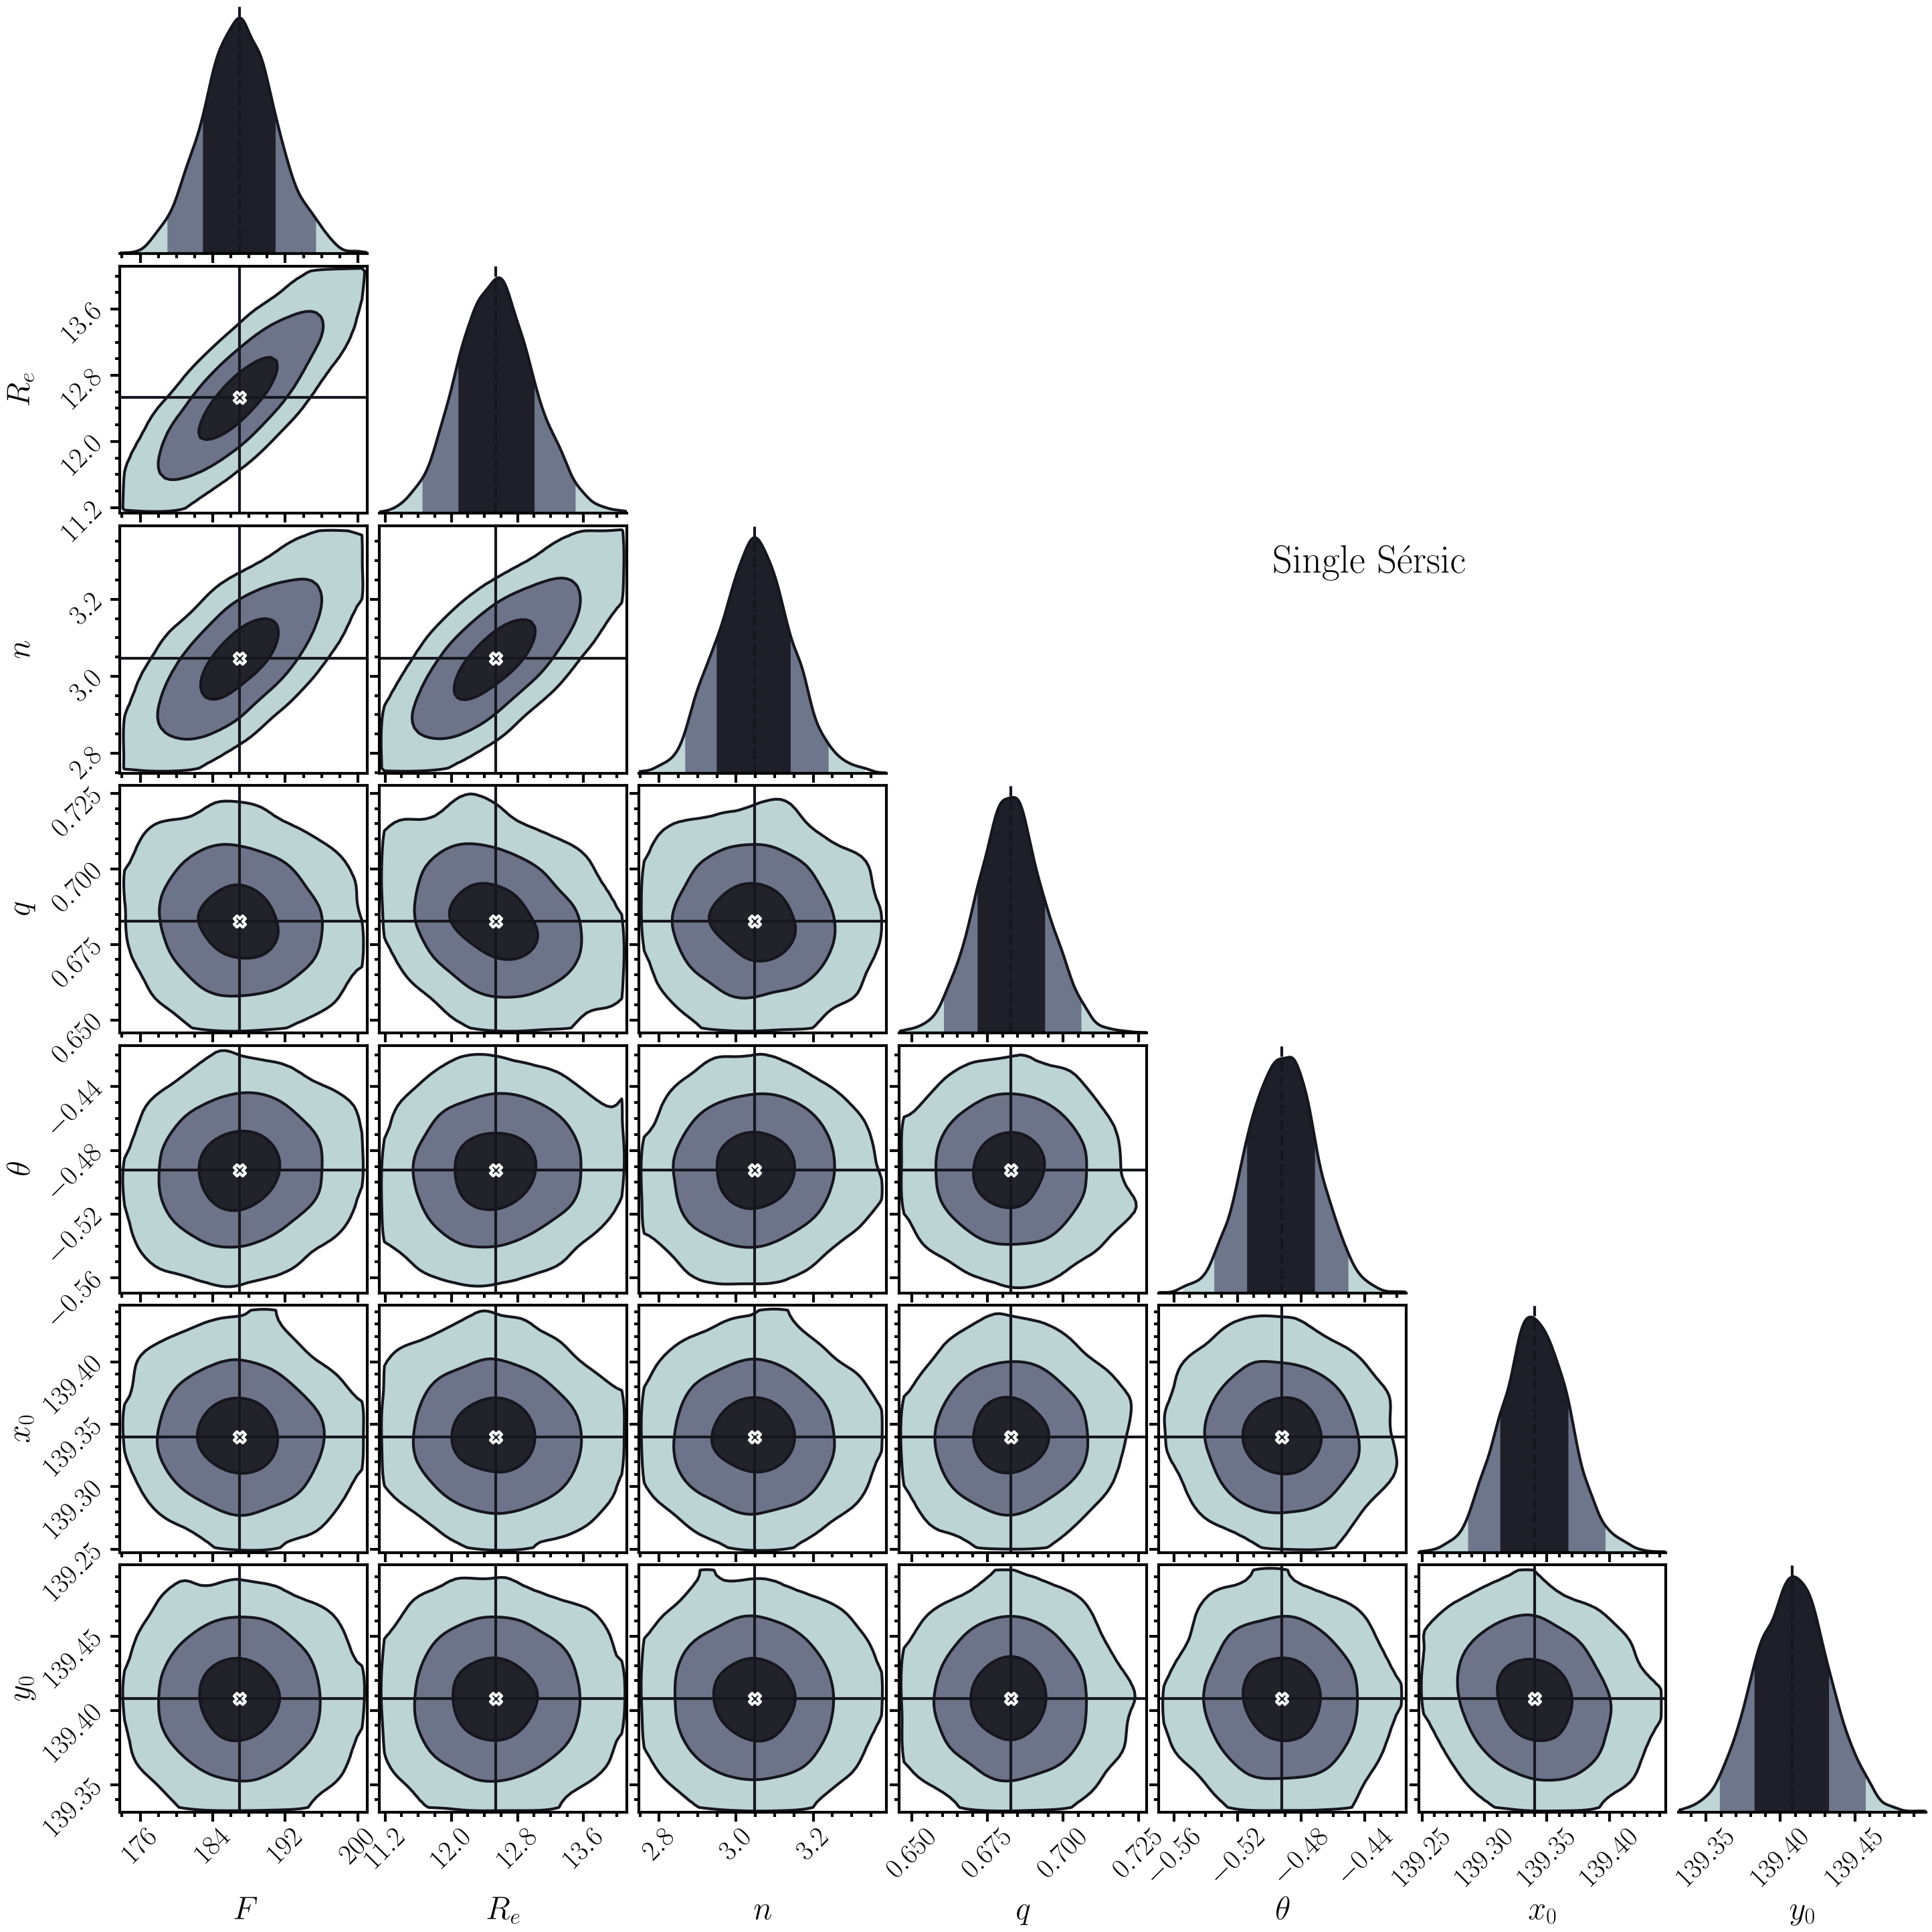

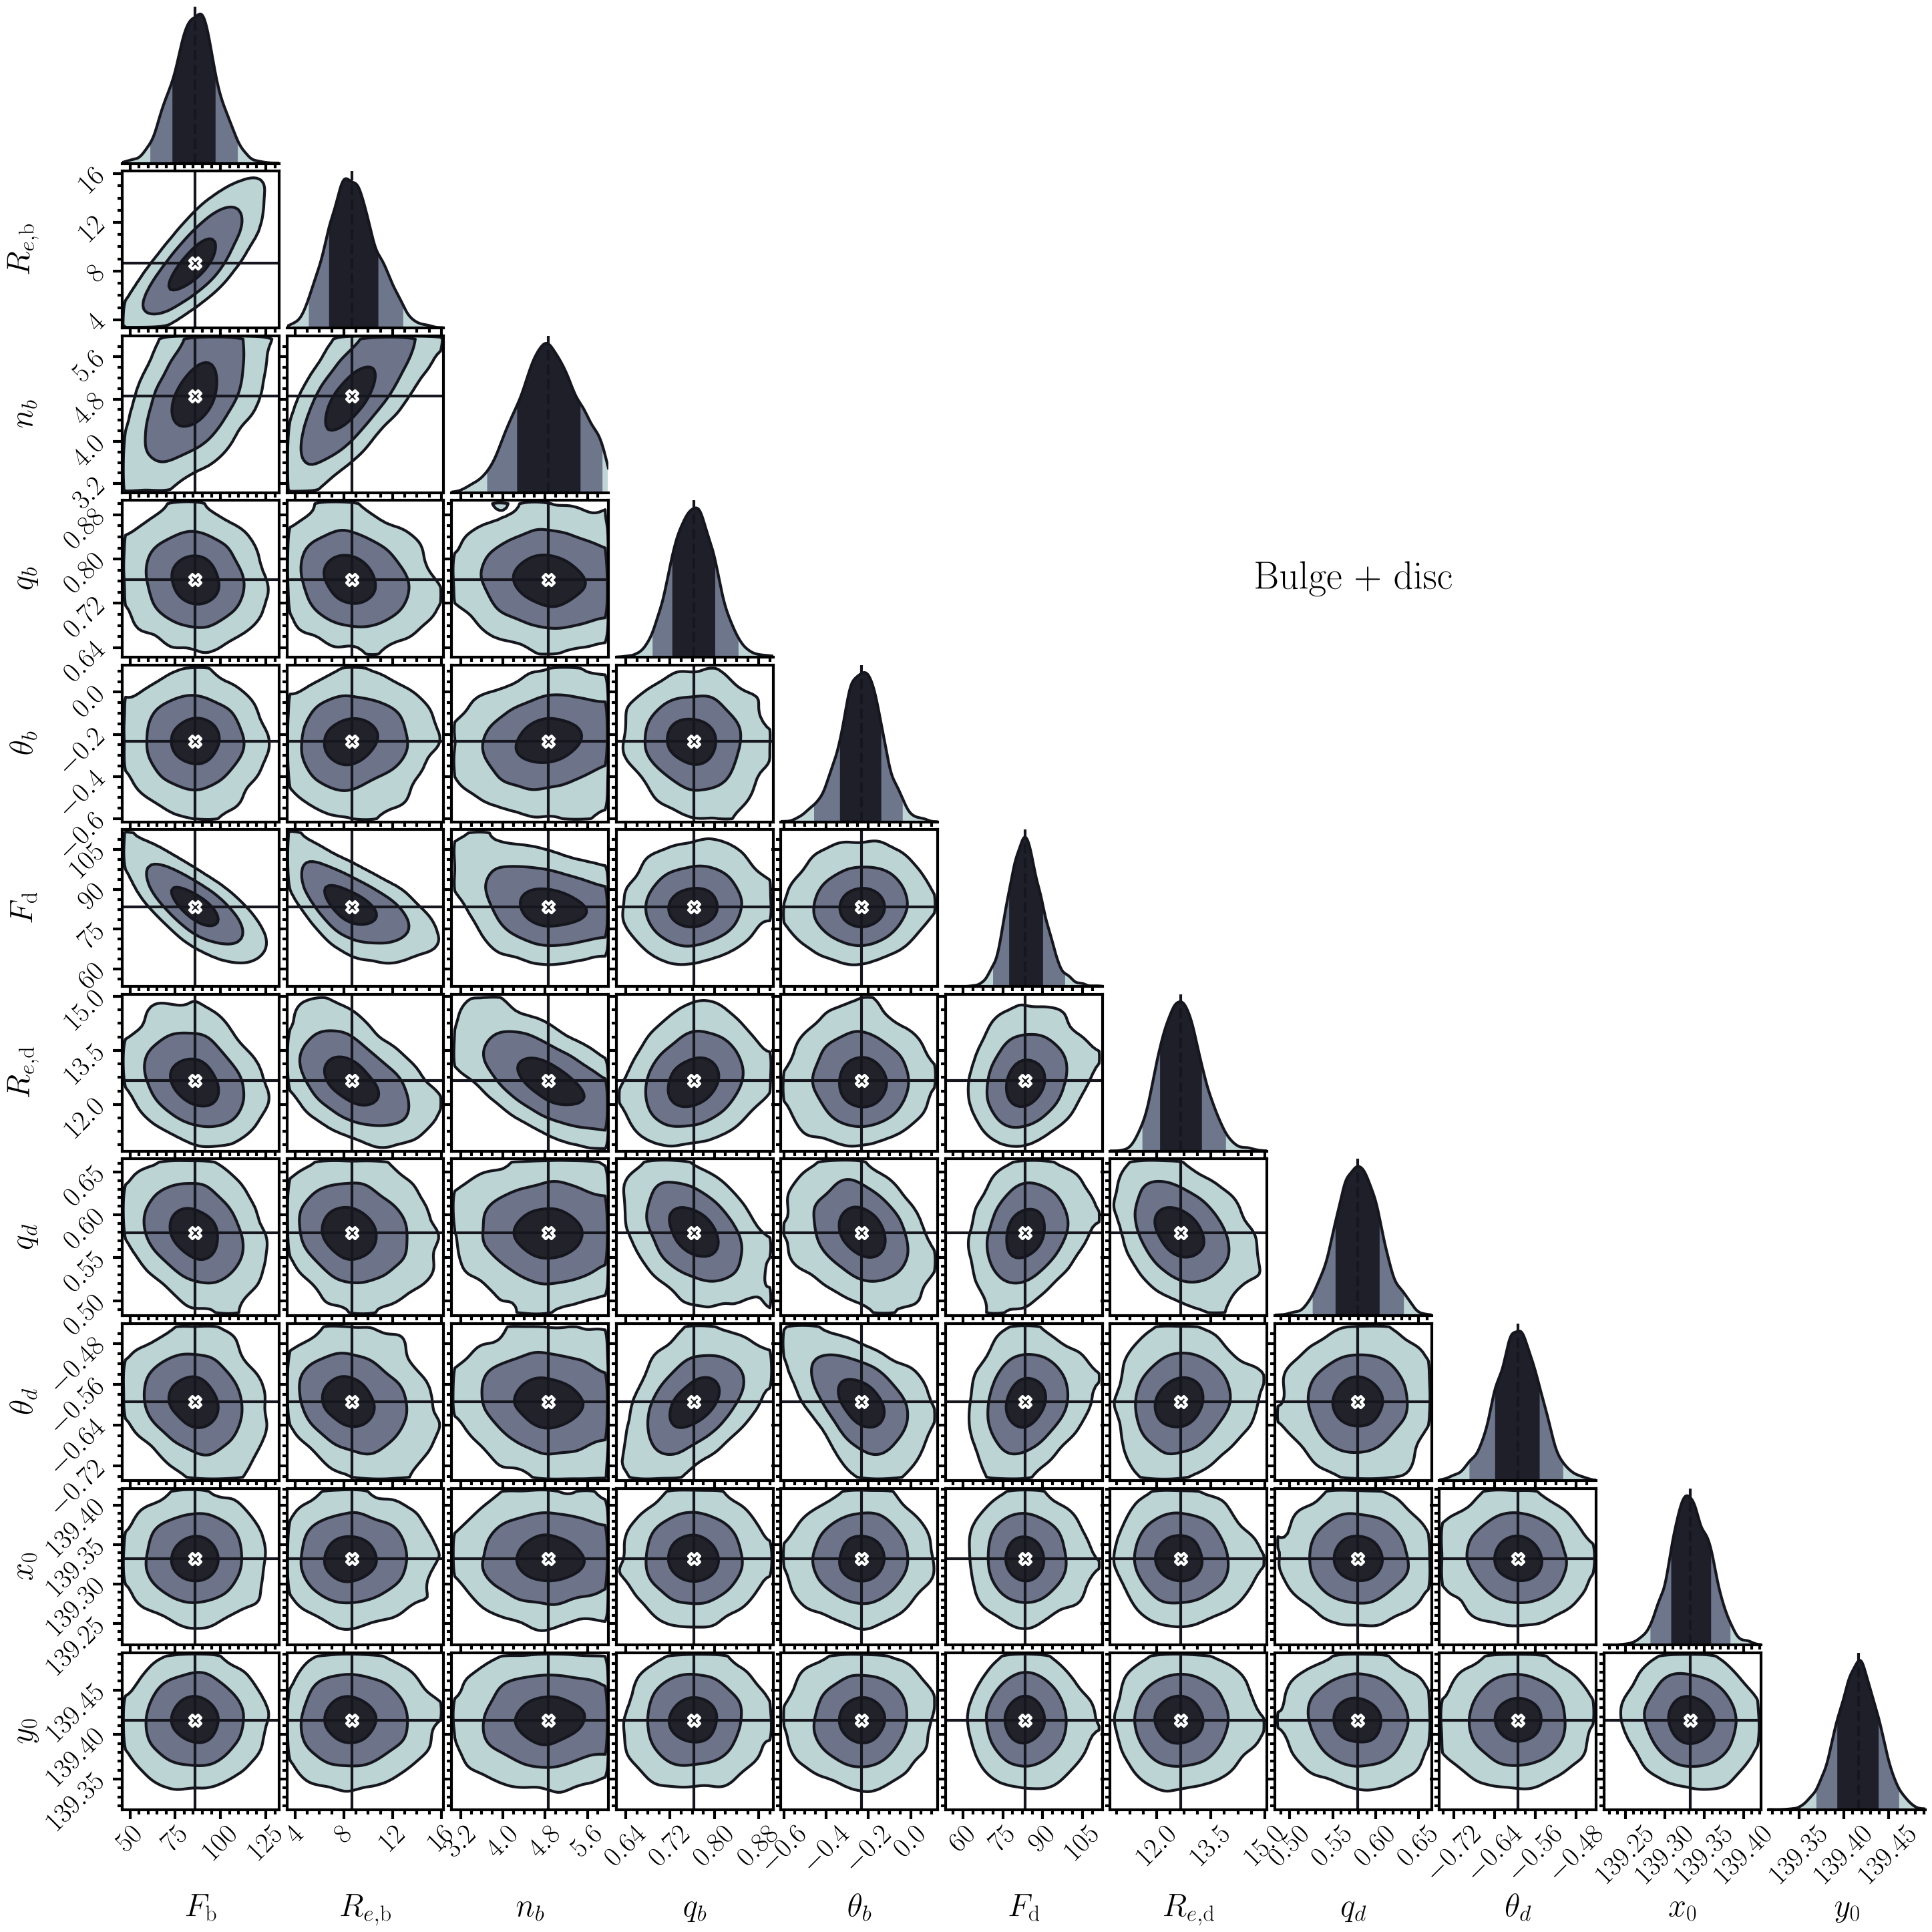

In [4]:
rng = np.random.default_rng(0)
for name, fit in models.items():
    post = np.load(fit / "posterior.npz")
    draw = rng.choice(len(post["weights"]), 4000, p=post["weights"] / post["weights"].sum())
    names = [str(n) for n in post["parameter_names"][:-1]]  # all but the background
    corner_plot(post["samples"][draw, :-1].T, parameter_labels=names, title=name)
    print(name, "ln Z =", round(float(post["evidence_logz"]), 2))

## What this shows

Both models describe the image to the noise (reduced $\chi^2$ 1.007 and 1.006), and the evidence prefers the bulge plus disc by $\Delta \ln Z = +64.5$. In a comparison with the input catalogue fixed before the fit, the single Sérsic agrees with its best description of the noiseless truth, while the bulge plus disc misses the position angles and axis ratios (total flux, bulge-to-total ratio and bulge size agree); faint unmasked neighbours inside the target's segment explain most of it, and the CRDS PSF does not reproduce the simulated stars exactly. One galaxy and one noise realization: a consistency test, not a validation.